# Снижение активности по картам: кому предложить возвращающую кампанию

**Банк «Меридиан» · аналитическая записка для департамента розничных продуктов**  
**Сравнение:** январь–июнь 2025 г. с январём–июнем 2024 г. · **данные:** январь 2024 — июнь 2025 г.  
**Основа:** очищенная выгрузка `01_analysis.ipynb`.

> Решение: кому направлять адресную коммуникацию.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 125, "axes.titlesize": 12, "axes.labelsize": 10,
                     "savefig.bbox": "tight"})

# Файлы должны находиться рядом с 02_report.ipynb.
clean = pd.read_parquet("clean_data.parquet")
log = pd.read_csv("cleaning_log.csv")
campaign = pd.read_csv("campaign_list.csv", dtype={"client_id": "string"})

for col in ["txn_datetime", "registration_date"]:
    clean[col] = pd.to_datetime(clean[col], errors="coerce")

# В parquet сохранены обе таблицы после внешнего объединения.
# Клиенты без транзакций сохранены, несвязанные транзакции — тоже.
clients = (clean.loc[clean["data_source"].isin(["both", "right_only"])]
           .drop_duplicates("client_id").copy())
transactions = clean.loc[clean["txn_id"].notna()].copy()

# Единая метрика: только успешные операции зарегистрированных клиентов,
# в пределах 01.01.2024–30.06.2025 (верхняя граница не включается).
activity = transactions.loc[
    transactions["status"].eq("успешно")
    & transactions["txn_datetime"].ge("2024-01-01")
    & transactions["txn_datetime"].lt("2025-07-01")
    & transactions["client_id"].isin(clients["client_id"])
].copy()
activity["year"] = activity["txn_datetime"].dt.year
activity["month"] = activity["txn_datetime"].dt.month

assert clients["client_id"].is_unique
assert campaign["client_id"].is_unique
assert set(campaign["client_id"]).issubset(set(clients["client_id"]))
assert campaign["client_id"].map(
    clients.set_index("client_id")["marketing_opt_in"]
).eq("Да").all()

# Ключевые агрегаты для последующих разделов отчёта.
monthly = activity.groupby(["year", "month"]).size().unstack(0)
first_half_2024 = int(monthly.loc[1:6, 2024].sum())
first_half_2025 = int(monthly.loc[1:6, 2025].sum())
h1_change = (first_half_2025 / first_half_2024 - 1) * 100

segment_year = pd.crosstab(activity["segment"], activity["year"])
channel_year = pd.crosstab(activity["channel"], activity["year"])
category_year = pd.crosstab(activity["category"], activity["year"])

for table in (segment_year, channel_year, category_year):
    table["2024/мес"] = table[2024] / 12
    table["2025/мес"] = table[2025] / 6
    table["Изменение, %"] = 100 * (table["2025/мес"] / table["2024/мес"] - 1)

# Частота включает даже клиентов с нулём операций.
metrics = clients[["client_id", "segment", "registration_date", "marketing_opt_in"]].copy()
n24 = activity.loc[activity["year"].eq(2024)].groupby("client_id").size()
n25 = activity.loc[activity["year"].eq(2025)].groupby("client_id").size()
metrics["f24"] = metrics["client_id"].map(n24).fillna(0) / 12
metrics["f25"] = metrics["client_id"].map(n25).fillna(0) / 6
metrics["change_abs"] = metrics["f25"] - metrics["f24"]
metrics["change_pct"] = (metrics["f25"] / metrics["f24"].replace(0, np.nan) - 1) * 100
metrics["full_period"] = metrics["registration_date"].le("2024-01-01")
metrics["significant_decline"] = (
    metrics["full_period"] & metrics["f24"].gt(0)
    & metrics["change_pct"].le(-30) & metrics["change_abs"].le(-2)
)

# Полная сверка выгрузки с результатами исследовательского ноутбука.
assert len(clients) == 5649 and len(transactions) == 624449
assert len(activity) == 576835 and len(campaign) == 999
assert campaign["group"].value_counts().to_dict() == {
    "Карточная": 485, "Продуктовая": 333, "Зарплатная": 181
}
print("Данные и список кампании загружены; ключевые размеры проверены.")

Данные и список кампании загружены; ключевые размеры проверены.


## 1. Главное

1. **Активность продолжила снижаться при сравнении одинаковых месяцев:** 189 188 успешных операций за январь–июнь 2024 г. против 167 811 за январь–июнь 2025 г. (**−11,3%**).
2. **Падение неравномерно:** среднемесячное количество операций в массовом сегменте уменьшилось на **32,0%**, в премиальном — на **5,1%**.
3. **Каналы расходятся по динамике:** пластиковая карта **−27,6%**, токен **+32,7%** по среднемесячному числу операций. Это не доказывает, что конкретные клиенты перешли между каналами.
4. **Под адресную кампанию отобраны 999 клиентов:** три непересекающиеся группы по 333, 485 и 181 человеку. Это **73,5%** от 1 359 клиентов с существенным снижением и маркетинговым согласием; лимит 2 000 не превышен.

## 2. Контекст

Департамент розничных продуктов хочет вернуть клиентов, которые стали заметно реже пользоваться картами. Требуется выделить не отдельные фамилии, а воспроизводимые группы, для каждой из которых можно разработать свою коммуникацию. Рекомендуется целевая кампания на **999 клиентов**, а не массовая рассылка. Результат отражает закономерности синтетической выгрузки, но не устанавливает причины поведения клиентов.

## 3. Данные и ограничения

Очищенный клиентский справочник содержит **5 649 клиентов**, а транзакционная часть — **624 449 уникальных операций**. Для оценки активности использованы **576 835 успешных операций** за период 01.01.2024–30.06.2025, связанных с клиентами справочника. Сохранившиеся в `clean_data.parquet` возвраты, отказы, записи за пределами периода и транзакции без карточки клиента не вошли в метрику.

**Метрика:** число успешных операций на одного клиента **в месяц**: за 2024 г. число операций делится на 12, за январь–июнь 2025 г. — на 6. Для проверки общей динамики дополнительно сравниваются **одинаковые первые полугодия**. Метрика не отражает величину чека, изменение расходов без изменения числа покупок, использование карт других банков и операции вне выгрузки. Данные включают несколько валют — суммирование сумм без конвертации было бы некорректным. Результаты описательные, не причинные.

In [ ]:
# Поэтапно показываем, какие записи попали в метрику.
funnel = pd.DataFrame([
    ["Уникальные транзакции после очистки", len(transactions)],
    ["Внутри периода 2024-01-01 — 2025-06-30", int(transactions["txn_datetime"].between(
        "2024-01-01", "2025-06-30 23:59:59.999999999").sum())],
    ["Успешные внутри периода", int((transactions["status"].eq("успешно") &
        transactions["txn_datetime"].ge("2024-01-01") &
        transactions["txn_datetime"].lt("2025-07-01")).sum())],
    ["Успешные, период, известный клиент", len(activity)],
], columns=["Этап отбора операций", "Число строк"])
display(funnel)

,Этап отбора операций,Число строк
0,Уникальные транзакции после очистки,624449
1,Внутри периода 2024-01-01 — 2025-06-30,624375
2,Успешные внутри периода,604457
3,"Успешные, период, известный клиент",576835


## 4. Находки

### 4.1. В каждом месяце первого полугодия 2025 года операций меньше, чем годом ранее

За январь–июнь 2024 года прошло **189 188** успешных операций, за те же месяцы 2025 года — **167 811**, то есть **на 11,3% меньше**. Сопоставление одинаковых месяцев уменьшает влияние календарной сезонности, но не устраняет все сезонные и внешние факторы.

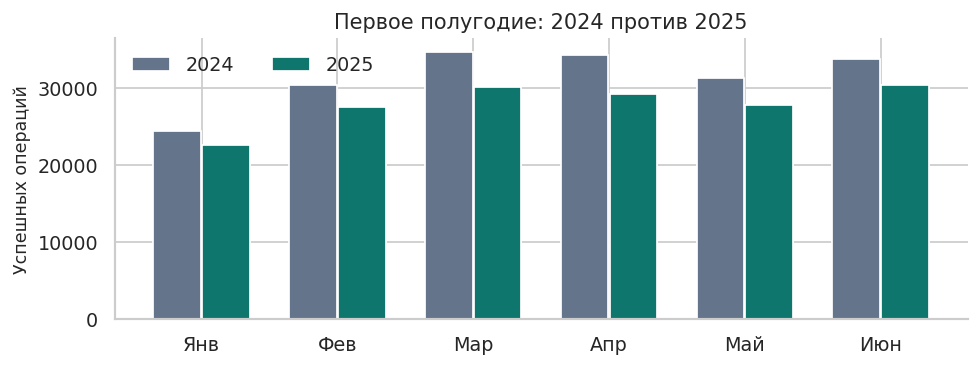

In [ ]:
fig, ax = plt.subplots(figsize=(8.0, 3.1))
x = np.arange(6)
ax.bar(x - .18, monthly.loc[1:6, 2024], width=.35, label="2024", color="#64748b")
ax.bar(x + .18, monthly.loc[1:6, 2025], width=.35, label="2025", color="#0f766e")
ax.set_xticks(x, ["Янв", "Фев", "Мар", "Апр", "Май", "Июн"])
ax.set_ylabel("Успешных операций")
ax.set_title("Первое полугодие: 2024 против 2025")
ax.legend(frameon=False, ncol=2)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 4.2. Снижение сосредоточено прежде всего в массовом сегменте

В массовом сегменте среднемесячная активность снизилась на **31,98%**, тогда как в премиальном — на **5,07%**, зарплатном — на **7,29%**, Private — на **7,35%**. Значит, нельзя описывать весь банк одним типичным сценарием снижения. Сегменты различаются по динамике, но это не объясняет её причины.

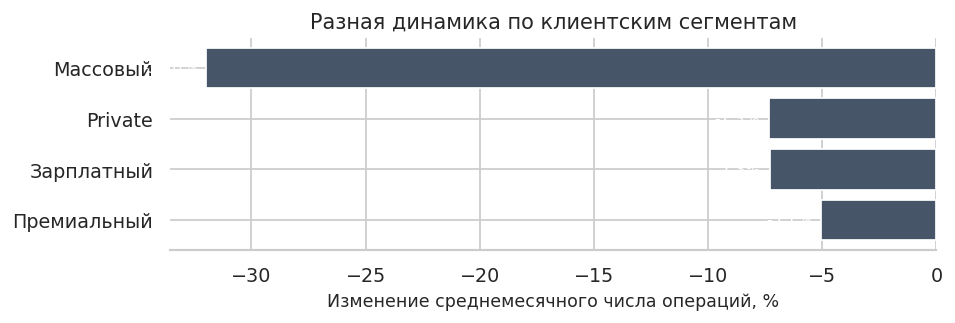

In [ ]:
plot = segment_year["Изменение, %"].sort_values()
fig, ax = plt.subplots(figsize=(7.8, 2.75))
ax.barh(plot.index, plot.values, color="#475569")
ax.set_xlabel("Изменение среднемесячного числа операций, %")
ax.set_title("Разная динамика по клиентским сегментам")
ax.invert_yaxis()
for i, v in enumerate(plot.values):
    ax.text(v - 0.4, i, f"{v:.1f}%", va="center", ha="right", color="white", fontsize=9)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

### 4.3. Пластиковая карта теряет операции, тогда как токен растёт

По среднемесячному числу успешных операций пластиковая карта показывает **−27,65%**, онлайн-банк — **−32,39%**, СБП — **−16,69%**, а токен — **+32,75%**. Рост токена на уровне банка не означает доказанного перехода тех же клиентов с пластиковой карты: для такого вывода нужен отдельный анализ индивидуальных траекторий.

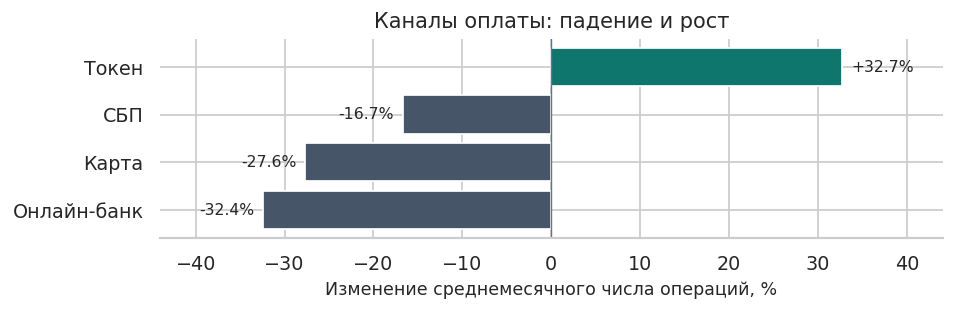

In [ ]:
plot = channel_year["Изменение, %"].sort_values()
fig, ax = plt.subplots(figsize=(7.8, 2.65))
colors = ["#0f766e" if v > 0 else "#475569" for v in plot.values]
ax.barh(plot.index, plot.values, color=colors)
ax.axvline(0, color="#64748b", linewidth=.8)
ax.set_xlabel("Изменение среднемесячного числа операций, %")
ax.set_title("Каналы оплаты: падение и рост")
for i, v in enumerate(plot.values):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.1f}%",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-44, 44)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

### 4.4. Больше всего в относительном выражении сократился транспорт

Среди категорий сильнее всего снизились операции в **транспорте (−34,21%)**. В продуктах сокращение составило **−18,14%**, но из-за высокой исходной частоты это около **1 631 операции в месяц** — крупнейшее абсолютное сокращение по категориям. Эти два показателя описывают разные стороны проблемы и не заменяют индивидуальный отбор.

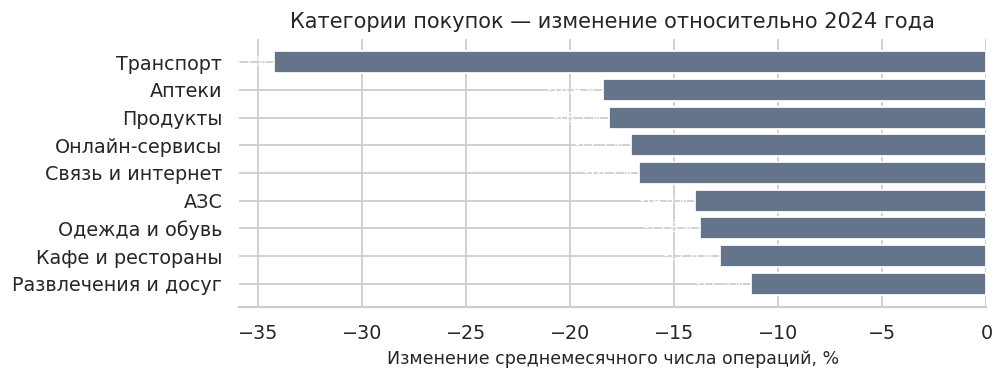

In [ ]:
plot = category_year["Изменение, %"].sort_values()
fig, ax = plt.subplots(figsize=(8.2, 3.2))
ax.barh(plot.index, plot.values, color="#64748b")
ax.invert_yaxis()
ax.set_xlabel("Изменение среднемесячного числа операций, %")
ax.set_title("Категории покупок — изменение относительно 2024 года")
for i,v in enumerate(plot.values):
    ax.text(v - .35, i, f"{v:.1f}%", ha="right", va="center", color="white",fontsize=8)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

## 5. Группы для кампании

**Отбор проходил в два этапа.** Первый — общий фильтр: клиент зарегистрирован **не позднее 01.01.2024**, имел ненулевую активность в 2024 году, а его **общее** среднемесячное количество успешных операций снизилось **не менее чем на 30% и одновременно не менее чем на 2 операции в месяц**. Для маркетинговой кампании обязательно `marketing_opt_in = «Да»`.

Второй этап — дополнительные тематические условия группы: для выбранной категории «Продукты» либо канала «Карта» снижение составило **минимум 1 операцию в месяц**, а вклад этого направления в общее чистое сокращение — **минимум 30%**. **Порог 1 операции относится только к категории или каналу, а не заменяет общий порог 2 операций. Оба условия применяются одновременно.**

У массовых клиентов признаки «Продукты» и «Карта» могли пересекаться. При пересечении сравнивалось **относительное снижение внутри категории и канала**; клиент относился к более выраженному направлению, при равенстве — к продуктовой группе. Зарплатные клиенты образуют отдельную группу. В окончательном списке каждый `client_id` встречается единожды.

In [ ]:
# Генерируем описание групп из реального списка кампании и транзакций.
rows = []
for label in ["Продуктовая", "Карточная", "Зарплатная"]:
    ids = campaign.loc[campaign["group"].eq(label), "client_id"]
    field, value = ("category", "Продукты") if label == "Продуктовая" else ("channel", "Карта")
    part = activity.loc[activity["client_id"].isin(ids) & activity[field].eq(value)]
    before = part["year"].eq(2024).sum() / (len(ids) * 12)
    after = part["year"].eq(2025).sum() / (len(ids) * 6)
    rows.append([label, len(ids), value, round(before,2), round(after,2),
                 round((after/before-1)*100,1)])
groups_table = pd.DataFrame(rows, columns=[
    "Группа", "Клиентов", "Направление", "2024, оп./мес.", "2025, оп./мес.", "Изменение, %"
])
display(groups_table)

# Проверяем повторяемость группового решения по исходным показателям.
candidates = metrics.loc[metrics["significant_decline"] & metrics["marketing_opt_in"].eq("Да")].copy()
for name, field, value in [("food", "category", "Продукты"), ("card", "channel", "Карта")]:
    subs = activity.loc[activity[field].eq(value)]
    b = subs.loc[subs["year"].eq(2024)].groupby("client_id").size()
    a = subs.loc[subs["year"].eq(2025)].groupby("client_id").size()
    old = candidates["client_id"].map(b).fillna(0)/12
    new = candidates["client_id"].map(a).fillna(0)/6
    candidates[name + "_loss"] = old - new
    candidates[name + "_decline_pct"] = (1 - new/old.replace(0,np.nan))*100
    candidates[name + "_share"] = (old - new)/(-candidates["change_abs"])

food_ok = candidates["segment"].eq("Массовый") & candidates["food_loss"].ge(1) & candidates["food_share"].ge(.30)
card_ok = candidates["segment"].eq("Массовый") & candidates["card_loss"].ge(1) & candidates["card_share"].ge(.30)
food_final = food_ok & (~card_ok | candidates["food_decline_pct"].ge(candidates["card_decline_pct"]))
card_final = card_ok & ~food_final
salary_final = candidates["segment"].eq("Зарплатный") & candidates["card_loss"].ge(1) & candidates["card_share"].ge(.30)
candidates["assigned"] = pd.NA
candidates.loc[food_final, "assigned"] = "Продуктовая"
candidates.loc[card_final, "assigned"] = "Карточная"
candidates.loc[salary_final, "assigned"] = "Зарплатная"
recalculated = candidates.loc[candidates["assigned"].notna(), ["client_id", "assigned"]].rename(columns={"assigned":"group"})
assert set(map(tuple, recalculated.itertuples(index=False, name=None))) == set(
    map(tuple, campaign.itertuples(index=False, name=None))
)
assert campaign["group"].value_counts().ge(150).all() and len(campaign) <= 2000
print("Правила воспроизвели все назначения campaign_list.csv: 999 из 999.")

,Группа,Клиентов,Направление,"2024, оп./мес.","2025, оп./мес.","Изменение, %"
0,Продуктовая,333,Продукты,2.39,0.59,-75.2
1,Карточная,485,Карта,4.18,1.43,-65.9
2,Зарплатная,181,Карта,4.80,1.90,-60.5


Правила воспроизвели все назначения campaign_list.csv: 999 из 999.


**Интерпретация и действия.** В продуктовой группе (**333 человека**) покупки продуктов сократились в среднем с **2,39 до 0,59 в месяц (−75,2%)**: уместно протестировать предложение для повседневных покупок. В карточной группе массового сегмента (**485 человек**) оплаты пластиковой картой снизились с **4,18 до 1,43 (−65,9%)**: возможна коммуникация о преимуществах оплаты картой. В зарплатной группе (**181 человек**) число таких операций уменьшилось с **4,80 до 1,90 (−60,5%)**: предложение можно адаптировать к зарплатному обслуживанию. Это **наблюдаемые источники изменения**, а не доказанные мотивы клиентов; эффективность акций требуется проверять отдельно.

## 6. Кого не включаем и почему

Причины применялись **последовательно**: сначала неполный базовый период, затем отсутствие существенного снижения, затем отсутствие согласия среди кандидатов и наконец несоответствие правилам трёх групп. Это взаимоисключающие причины, а не независимые множества.

In [ ]:
selection = metrics[["client_id", "full_period", "significant_decline", "marketing_opt_in"]].copy()
selection["in_campaign"] = selection["client_id"].isin(campaign["client_id"])
selection["reason"] = "В кампании"
selection.loc[~selection["full_period"], "reason"] = "Недостаточная история"
selection.loc[selection["full_period"] & ~selection["significant_decline"], "reason"] = "Нет существенного снижения"
selection.loc[selection["significant_decline"] & selection["marketing_opt_in"].ne("Да"), "reason"] = "Нет согласия"
selection.loc[selection["significant_decline"] & selection["marketing_opt_in"].eq("Да") & ~selection["in_campaign"], "reason"] = "Не соответствует правилам групп"
reason_order = ["Недостаточная история", "Нет существенного снижения", "Нет согласия",
                "Не соответствует правилам групп", "В кампании"]
exclusions = selection["reason"].value_counts().reindex(reason_order, fill_value=0)
display(exclusions.rename_axis("Категория").reset_index(name="Клиентов"))
assert exclusions.sum() == len(clients)
assert exclusions["В кампании"] == len(campaign)

,Категория,Клиентов
0,Недостаточная история,137
1,Нет существенного снижения,3989
2,Нет согласия,164
3,Не соответствует правилам групп,360
4,В кампании,999


**Решение:** 137 человек имеют неполную базовую историю и не сопоставимы за полный 2024 год; 3 989 не отвечают порогу существенного снижения; 164 кандидата не дали согласия; ещё 360 имеют существенное снижение и согласие, но не подходят под тематические правила. Всего **4 650 клиентов** не включены. Последняя категория не объявляется «неинтересной»: она остаётся резервом для отдельного исследования, а не для этой кампании.

## 7. Что проверили и что не подтвердилось

- **Одинаковое снижение во всех сегментах.** Не подтвердилось: массовый сегмент **−31,98%**, премиальный **−5,07%** по среднемесячному числу операций.
- **Снижение по всем платёжным каналам.** Не подтвердилось на уровне всего банка: пластиковая карта **−27,65%**, но токен **+32,75%**.
- **Одинаковая динамика всех категорий.** Не подтвердилась: транспорт **−34,21%**, развлечения и досуг **−11,30%**.

Отдельно проверено сравнение одинаковых полугодий (**−11,3%**), но **полностью исключить сезонное влияние нельзя**. Поэтому утверждение «сезонность не влияет» в число опровергнутых гипотез не включено.

## 8. Приложение

### 8.1. Сводка журнала изменений

Ниже представлены основные решения; полный журнал хранится в `cleaning_log.csv`. Количество затронутых строк относится к **конкретному действию** и не суммируется между строками (одна запись могла затрагиваться несколькими проверками).

In [ ]:
# Выбираем девять наиболее значимых типов решений из полного журнала.
key_issues = [
    ("clients", "Полные дубликаты"),
    ("transactions", "Полные дубликаты"),
    ("txn_id", "Разная точность записи даты"),
    ("client_id", "Повторные идентификаторы"),
    ("city", "Различные написания городов"),
    ("segment", "Противоречивые сегменты"),
    ("category", "Разные названия категорий"),
    ("monthly_income", "Служебное значение дохода"),
    ("mcc_code / category", "Несовпадение признаков"),
]
log_summary = pd.concat([
    log.loc[log["field"].eq(field) & log["issue"].eq(issue)]
    for field, issue in key_issues
], ignore_index=True)
assert len(log_summary) == len(key_issues)
display(log_summary[["field", "issue", "n_rows", "action"]].rename(columns={
    "field":"Поле", "issue":"Нарушение", "n_rows":"Строк", "action":"Действие"
}))

,Поле,Нарушение,Строк,Действие
0,clients,Полные дубликаты,40,удалено
1,transactions,Полные дубликаты,1279,удалено
2,txn_id,Разная точность записи даты,221,удалено
3,client_id,Повторные идентификаторы,15,удалено
4,city,Различные написания городов,1632,нормализовано
5,segment,Противоречивые сегменты,20,заменено
6,category,Разные названия категорий,52125,нормализовано
7,monthly_income,Служебное значение дохода,57,заменено
8,mcc_code / category,Несовпадение признаков,1679,оставлено


### 8.2. Методика и воспроизводимость

- **Источник:** `clean_data.parquet` — объединение после очистки; `cleaning_log.csv` — полный журнал; `campaign_list.csv` — финальный список. Из объединения восстановлены 5 649 клиентов (уникальный `client_id`) и 624 449 операций (уникальный `txn_id`).
- **Фильтр активности:** `status == "успешно"`, дата `>= 2024-01-01` и `< 2025-07-01`, известный `client_id`. Отменённые операции и возвраты не учитываются; итог — 576 835 операций. Для сравнения выбран год 2024 (12 месяцев) и январь–июнь 2025 (6 месяцев).
- **Частота:** `f24 = число операций за 2024 / 12`; `f25 = число операций за январь–июнь 2025 / 6`; `Δ = f25 − f24`; `%Δ = (f25 / f24 − 1) × 100%` при `f24 > 0`. Клиенты без операций включены в базу с частотой 0; процентное изменение для нулевого знаменателя не определено.
- **Кандидат:** дата регистрации `<= 2024-01-01`, `f24 > 0`, `%Δ <= −30%`, `Δ <= −2 оп./мес.`; обязательное согласие `marketing_opt_in == "Да"`. Всего 1 523 кандидата, из них 1 359 с согласием.
- **Дополнительное тематическое условие:** только для уже прошедших общий фильтр клиентов массового/зарплатного сегмента; `food_loss` или `card_loss >= 1 оп./мес.` и вклад в общее чистое снижение `>= 30%`. **Одна операция — порог отдельной категории/канала; две операции — обязательный порог общего снижения.** При пересечении продуктовой и карточной групп в массовом сегменте выигрывает большее *относительное снижение данного направления*; при равенстве — продукты.
- **Ограничения:** период 2025 г. неполный; количество операций не равно расходам или прибыльности; в данных есть RUB, USD и EUR, без конвертации сумм; изменение канала не доказывает переход конкретного клиента; наблюдаемые связи не объясняют причины отказа от платежей.

### 8.3. Использование ИИ

ИИ-ассистент использовался для разъяснения синтаксиса Python и pandas, обсуждения критериев снижения и структуры аналитического отчёта. Он также помогал подготовить код визуализаций и проверки воспроизводимости. Выбор групп, их ограничения и интерпретации проверены на загруженных данных с помощью расчётов и автоматических проверок. Предложения ИИ не рассматривались как самостоятельное доказательство причин снижения активности.

In [ ]:
# Контрольная ячейка: результаты должны остаться согласованными при запуске сверху вниз.
assert first_half_2024 == 189188 and first_half_2025 == 167811
assert int(metrics["significant_decline"].sum()) == 1523
assert int((metrics["significant_decline"] & metrics["marketing_opt_in"].eq("Да")).sum()) == 1359
assert (exclusions.loc[reason_order].values == [137,3989,164,360,999]).all()
assert len(log) == 26
print("ИТОГ: расчёты воспроизводимы; 3 группы, 999 клиентов, 4 графика.")

ИТОГ: расчёты воспроизводимы; 3 группы, 999 клиентов, 4 графика.
